# 06 — Model Evaluation, Customer Segment Interpretation and Business Recommendations

## 1. Introduction

This notebook presents the final evaluation and interpretation of the customer segmentation models developed in the preceding modelling phase. The purpose is not merely to identify a model with favourable validation scores, but to determine whether the resulting customer groups are sufficiently distinct, stable, interpretable and useful for addressing the project’s research questions.

The analysis uses the customer-level features and scaled modelling datasets prepared in **Notebook 04**, together with the K-Means and Agglomerative Hierarchical Clustering experiments conducted in **Notebook 05**. It evaluates candidate solutions across the RFM, Extended and Reduced Extended feature sets, then develops detailed profiles of the selected customer segments.

The notebook also examines the geographical distribution of the identified segments using country information from the original transaction data. Country is used only for supplementary post-clustering profiling; it is not included as a clustering input.

### Project research question

**Can unsupervised machine learning identify meaningful customer segments based on purchasing behaviour, spending patterns and transaction frequency?**

### Objectives

1. Verify the customer-level and model-ready datasets used for final evaluation.
2. Recalculate and compare the selected candidate models using internal clustering metrics.
3. Select and justify a final segmentation model using quantitative and practical evidence.
4. Interpret the final clusters using RFM and supplementary behavioural variables.
5. Examine the distribution of customer segments across countries.
6. Translate the segment profiles into actionable, testable business recommendations.
7. Discuss analytical limitations and responsible use of customer segmentation.

### Evaluation framework

The model assessment considers:

- **Silhouette Score:** higher values indicate better separation and cohesion.
- **Davies–Bouldin Index:** lower values indicate more compact and better-separated clusters.
- **Calinski–Harabasz Index:** higher values indicate greater between-cluster dispersion relative to within-cluster dispersion.
- Cluster sizes and customer-level profile differences.
- Stability and sensitivity findings from the preceding modelling phase.
- Interpretability and practical usefulness of the resulting segments.

No single metric is treated as sufficient evidence of a good segmentation. The evaluation combines internal metrics with profile differentiation, robustness checks and business interpretability.

### Important interpretation principles

- `CustomerID` is an identifier used to connect records and profile customers; it is never a clustering feature.
- Cluster numbers are arbitrary labels. Descriptive names are assigned only after examining the resulting profiles.
- Monetary values are expressed in the dataset's currency (£).
- Recency is measured in days; a higher value means a longer time since the customer's last recorded purchase.
- The results describe historical purchasing behaviour. They do not establish causality or predict future behaviour.

## 2. Environment setup and input verification

The first step is to import the required libraries, locate the project directory and verify that the processed datasets from the previous phase are available.

The notebook expects to be run either from the project root or from its `notebooks` directory. The path check below searches these expected locations and stops with a clear error if the required processed data cannot be found.

In [1]:
# Section 2 – Import libraries and verify Phase 6 inputs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# Locate the project directory from the current working directory.
cwd = Path.cwd().resolve()
candidate_roots = [cwd, cwd.parent, cwd.parent.parent]

PROJECT_ROOT = None
for candidate in candidate_roots:
    if (candidate / "data" / "processed").exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project data/processed directory. "
        "Run this notebook from the project root or its notebooks directory."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

required_files = [
    "original_customer_features.csv",
    "original_rfm_standard_scaled.csv",
    "original_extended_standard_scaled.csv",
    "original_reduced_extended_standard_scaled.csv"
]

missing_files = [
    filename for filename in required_files
    if not (PROCESSED_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required Phase 6 input files are missing: "
        + ", ".join(missing_files)
    )

print("PHASE 6 INPUT VERIFICATION")
print("--------------------------------")
print("Project root:", PROJECT_ROOT)
print("Processed data directory:", PROCESSED_DIR)

for filename in required_files:
    file_path = PROCESSED_DIR / filename
    temp_df = pd.read_csv(file_path)
    print(f"\n{filename}")
    print("Shape:", temp_df.shape)
    print("Missing values:", temp_df.isnull().sum().sum())


PHASE 6 INPUT VERIFICATION
--------------------------------
Project root: C:\Users\yadav\OneDrive\Desktop\Online_Retail_Customer_Segmentation
Processed data directory: C:\Users\yadav\OneDrive\Desktop\Online_Retail_Customer_Segmentation\data\processed

original_customer_features.csv
Shape: (4335, 9)
Missing values: 1505

original_rfm_standard_scaled.csv
Shape: (4335, 4)
Missing values: 0

original_extended_standard_scaled.csv
Shape: (4335, 7)
Missing values: 0

original_reduced_extended_standard_scaled.csv
Shape: (4335, 6)
Missing values: 0


**Interpretation.** The customer feature file contains 4,335 customer records and has 1,505 missing values, while the three scaled model-input files contain no missing values. The missing values in the customer feature file are examined next rather than automatically treated as data-quality errors. The scaled files are the inputs used to refit and compare the candidate clustering models in this notebook.

## 3. Inspect customer-level features and structural missingness

The customer-level feature table contains one row per customer. It includes the three RFM variables, additional behavioural variables and the date of the customer's last purchase.

`PurchaseRegularity` is missing for some customers. Before deciding how to handle this, the analysis checks whether missingness is associated with a particular purchase-frequency pattern.

In [2]:
# Load the original customer-level features

customer_features = pd.read_csv(
    PROCESSED_DIR / "original_customer_features.csv"
)

print("CUSTOMER FEATURE DATASET")
print("--------------------------------")

print("Shape:", customer_features.shape)

print("\nColumns:")
print(customer_features.columns.tolist())

print("\nMissing values by column:")
print(
    customer_features.isnull()
    .sum()
    .sort_values(ascending=False)
)

print("\nData types:")
print(customer_features.dtypes)

print("\nUnique customer IDs:")
print(customer_features["CustomerID"].nunique())

print("\nDuplicate customer IDs:")
print(customer_features["CustomerID"].duplicated().sum())

print("\nSample records:")
display(customer_features.head())

CUSTOMER FEATURE DATASET
--------------------------------
Shape: (4335, 9)

Columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'LastPurchaseDate', 'AverageOrderValue', 'TotalQuantity', 'ProductDiversity', 'PurchaseRegularity']

Missing values by column:
PurchaseRegularity    1505
CustomerID               0
Recency                  0
Monetary                 0
Frequency                0
LastPurchaseDate         0
AverageOrderValue        0
TotalQuantity            0
ProductDiversity         0
dtype: int64

Data types:
CustomerID            float64
Recency                 int64
Frequency               int64
Monetary              float64
LastPurchaseDate          str
AverageOrderValue     float64
TotalQuantity           int64
ProductDiversity        int64
PurchaseRegularity    float64
dtype: object

Unique customer IDs:
4335

Duplicate customer IDs:
0

Sample records:


,CustomerID,Recency,Frequency,Monetary,LastPurchaseDate,AverageOrderValue,TotalQuantity,ProductDiversity,PurchaseRegularity
0,12346.0,326,1,77183.60,2011-01-18 10:01:00,77183.600000,74215,1,NaN
1,12347.0,3,7,4310.00,2011-12-07 15:52:00,615.714286,2458,103,60.839699
2,12348.0,76,4,1437.24,2011-09-25 13:13:00,359.310000,2332,21,94.250926
3,12349.0,19,1,1457.55,2011-11-21 09:51:00,1457.550000,630,72,NaN
4,12350.0,311,1,294.40,2011-02-02 16:01:00,294.400000,196,16,NaN


In [3]:
# Check whether missing PurchaseRegularity is associated with single-invoice customers

print("PURCHASE REGULARITY MISSINGNESS CHECK")
print("--------------------------------")

missing_regularity = customer_features[
    customer_features["PurchaseRegularity"].isna()
]

available_regularity = customer_features[
    customer_features["PurchaseRegularity"].notna()
]

print("Customers with missing PurchaseRegularity:",
      len(missing_regularity))

print("Customers with available PurchaseRegularity:",
      len(available_regularity))

print("\nFrequency distribution among customers with missing values:")
display(missing_regularity["Frequency"].value_counts().sort_index())

print("\nFrequency distribution among customers with available values:")
display(available_regularity["Frequency"].value_counts().sort_index())

print("\nMissing PurchaseRegularity among customers with Frequency > 1:",
      customer_features.loc[
          customer_features["Frequency"] > 1,
          "PurchaseRegularity"
      ].isna().sum())

print("\nMissing PurchaseRegularity among customers with Frequency = 1:",
      customer_features.loc[
          customer_features["Frequency"] == 1,
          "PurchaseRegularity"
      ].isna().sum())

PURCHASE REGULARITY MISSINGNESS CHECK
--------------------------------
Customers with missing PurchaseRegularity: 1505
Customers with available PurchaseRegularity: 2830

Frequency distribution among customers with missing values:


Frequency
1    1505
Name: count, dtype: int64


Frequency distribution among customers with available values:


Frequency
2      830
3      504
4      394
5      237
6      173
7      138
8       98
9       69
10      55
11      54
12      43
13      29
14      19
15      26
16      10
17      19
18      13
19      12
20      13
21      10
22       6
23       4
24       3
25       8
26       7
27       4
28       6
29       1
30       3
31       4
32       2
33       2
34       3
35       1
36       1
37       4
39       2
41       1
44       2
46       1
47       2
48       1
50       1
51       1
55       2
57       1
60       1
62       2
72       1
86       1
91       2
97       1
124      1
199      1
206      1
Name: count, dtype: int64


Missing PurchaseRegularity among customers with Frequency > 1: 0

Missing PurchaseRegularity among customers with Frequency = 1: 1505


**Interpretation.** The dataset contains 4,335 unique customers and no duplicate customer identifiers. The only missing feature is `PurchaseRegularity`, with 1,505 missing observations. All 1,505 customers with a missing value have a purchase frequency of exactly one invoice; no customer with more than one invoice has a missing value.

This is **structural missingness**, not evidence that the values were simply omitted during data collection: a purchase interval cannot be calculated from a single observed invoice. These customers are retained in the analysis. `PurchaseRegularity` is not used as a clustering input, and the missing values are not imputed.

## 4. Load and verify the modelling datasets

Three model-ready datasets are used:

- **RFM:** Recency, Frequency and Monetary.
- **Extended:** RFM plus Average Order Value, Total Quantity and Product Diversity.
- **Reduced Extended:** the Extended set without Total Quantity, which was removed in the preceding phase because of its strong overlap with Monetary.

The customer identifier is retained to verify record alignment but is excluded from every feature matrix.

In [4]:
# Section 4 – Load and verify modelling datasets

rfm_scaled = pd.read_csv(
    PROCESSED_DIR / "original_rfm_standard_scaled.csv"
)

extended_scaled = pd.read_csv(
    PROCESSED_DIR / "original_extended_standard_scaled.csv"
)

reduced_extended_scaled = pd.read_csv(
    PROCESSED_DIR / "original_reduced_extended_standard_scaled.csv"
)

print("MODELLING DATASET VERIFICATION")
print("--------------------------------")

datasets = {
    "RFM": rfm_scaled,
    "Extended": extended_scaled,
    "Reduced Extended": reduced_extended_scaled
}

for name, data in datasets.items():
    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Unique customers:", data["CustomerID"].nunique())
    print("Duplicate CustomerIDs:", data["CustomerID"].duplicated().sum())
    print("Missing values:", data.isnull().sum().sum())

# Verify that all modelling datasets contain the same customers
same_customers = (
    set(rfm_scaled["CustomerID"])
    == set(extended_scaled["CustomerID"])
    == set(reduced_extended_scaled["CustomerID"])
)

print("\nDo all three datasets contain the same customers?", same_customers)

MODELLING DATASET VERIFICATION
--------------------------------

RFM
Shape: (4335, 4)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary']
Unique customers: 4335
Duplicate CustomerIDs: 0
Missing values: 0

Extended
Shape: (4335, 7)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'TotalQuantity', 'ProductDiversity']
Unique customers: 4335
Duplicate CustomerIDs: 0
Missing values: 0

Reduced Extended
Shape: (4335, 6)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'ProductDiversity']
Unique customers: 4335
Duplicate CustomerIDs: 0
Missing values: 0

Do all three datasets contain the same customers? True


**Interpretation.** Each modelling dataset contains the same 4,335 unique customers, with no duplicate customer identifiers and no missing values. The RFM, Extended and Reduced Extended inputs contain three, six and five clustering variables respectively, in addition to the identifier column.

The checks establish that all candidate models are evaluated on the same customer population. The model-fitting code below explicitly excludes `CustomerID`, ensuring that an identifier cannot influence distances or cluster assignments.

## 5. Final candidate model evaluation and selection

The candidate models are refitted using the saved, standard-scaled inputs so that their evaluation metrics can be compared in a consistent and reproducible manner.

The candidates include RFM K-Means with three clusters; RFM Hierarchical Clustering with two and three clusters; Extended K-Means and Hierarchical Clustering with two clusters; and Reduced Extended K-Means with two clusters.

For Silhouette and Calinski–Harabasz, higher values are preferred. For Davies–Bouldin, lower values are preferred.

In [5]:
# Section 5 – Recalculate evaluation metrics for final model candidates

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Prepare feature matrices by excluding CustomerID
X_rfm = rfm_scaled.drop(columns=["CustomerID"])

X_extended = extended_scaled.drop(columns=["CustomerID"])

X_reduced_extended = reduced_extended_scaled.drop(
    columns=["CustomerID"]
)

# Define candidate models
candidate_models = {
    "RFM | K-Means | K=3": (
        X_rfm,
        KMeans(n_clusters=3, random_state=42, n_init=20)
    ),

    "RFM | Hierarchical | K=2": (
        X_rfm,
        AgglomerativeClustering(n_clusters=2, linkage="ward")
    ),

    "RFM | Hierarchical | K=3": (
        X_rfm,
        AgglomerativeClustering(n_clusters=3, linkage="ward")
    ),

    "Extended | K-Means | K=2": (
        X_extended,
        KMeans(n_clusters=2, random_state=42, n_init=20)
    ),

    "Extended | Hierarchical | K=2": (
        X_extended,
        AgglomerativeClustering(n_clusters=2, linkage="ward")
    ),

    "Reduced Extended | K-Means | K=2": (
        X_reduced_extended,
        KMeans(n_clusters=2, random_state=42, n_init=20)
    )
}

# Fit models and calculate evaluation metrics
final_model_results = []
final_model_labels = {}

for model_name, (X, model) in candidate_models.items():

    labels = model.fit_predict(X)

    final_model_labels[model_name] = labels

    final_model_results.append({
        "Model": model_name,
        "Number_of_Clusters": len(np.unique(labels)),
        "Silhouette_Score": silhouette_score(X, labels),
        "Davies_Bouldin_Index": davies_bouldin_score(X, labels),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X, labels)
    })

# Create comparison table
final_model_comparison = pd.DataFrame(final_model_results)

final_model_comparison = final_model_comparison.sort_values(
    by="Silhouette_Score",
    ascending=False
).reset_index(drop=True)

print("FINAL CANDIDATE MODEL COMPARISON")
print("--------------------------------")

display(
    final_model_comparison.round(4)
)

FINAL CANDIDATE MODEL COMPARISON
--------------------------------


,Model,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,RFM | K-Means | K=3,3,0.4151,0.8269,4378.5206
1,RFM | Hierarchical | K=2,2,0.3965,0.8371,3276.0686
2,RFM | Hierarchical | K=3,3,0.3956,0.8669,4151.0791
3,Extended | K-Means | K=2,2,0.3511,1.0616,3116.7941
4,Reduced Extended | K-Means | K=2,2,0.3360,1.1176,2802.5822
5,Extended | Hierarchical | K=2,2,0.3237,1.0306,2510.9298


**Interpretation of candidate model comparison**

The RFM K-Means solution with three clusters achieved the strongest results among the six evaluated candidates:

- Silhouette Score: **0.4151**
- Davies–Bouldin Index: **0.8269**
- Calinski–Harabasz Index: **4,378.5206**

It ranked favourably across all three internal metrics in this candidate set. The RFM Hierarchical solutions were the closest alternatives, while the Extended and Reduced Extended candidates did not produce stronger internal evaluation scores in the experiments conducted.

An important qualification is that the RFM and extended models operate in feature spaces with different numbers and types of variables. Internal metrics are therefore not perfectly like-for-like across all feature sets. The scores are considered alongside the customer profiles, robustness checks and interpretability rather than used as the sole basis for selection.

**Model selection decision:** RFM K-Means with K=3 is retained as the preferred final segmentation because it combines the strongest observed internal metrics in the candidate comparison with a clear and commercially interpretable three-segment solution.

## 6. Profile the selected RFM K-Means solution

The selected model is RFM K-Means with three clusters. Cluster labels are arbitrary numerical identifiers generated by the algorithm. The descriptive names used in the remainder of the notebook are assigned after examining the customer-level profiles.

To avoid relying on the row order of separate CSV files, the cluster labels are first associated with the `CustomerID` values from the scaled RFM input and then merged with the original customer features.

In [6]:
# Section 6 – Fit selected RFM K-Means model and create aligned customer profiles

selected_model_name = "RFM | K-Means | K=3"
rfm_kmeans_labels = final_model_labels[selected_model_name]

# Attach labels to the exact customer IDs used by the RFM model.
rfm_cluster_assignments = rfm_scaled[["CustomerID"]].copy()
rfm_cluster_assignments["Cluster"] = rfm_kmeans_labels

# Merge by CustomerID to guarantee correct customer-to-cluster alignment.
rfm_profile_data = customer_features.merge(
    rfm_cluster_assignments,
    on="CustomerID",
    how="inner",
    validate="one_to_one"
)

if len(rfm_profile_data) != len(customer_features):
    raise ValueError("Customer-to-cluster merge did not retain every customer.")

if rfm_profile_data["Cluster"].isna().any():
    raise ValueError("Some customers do not have a cluster assignment.")

cluster_labels = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

# Cluster sizes and proportions
cluster_sizes = (
    rfm_profile_data["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Customer_Count")
    .to_frame()
)

cluster_sizes["Customer_Percentage"] = (
    cluster_sizes["Customer_Count"] / len(rfm_profile_data) * 100
)
cluster_sizes["Segment"] = cluster_sizes.index.map(cluster_labels)

# Mean and median RFM profiles
profile_variables = ["Recency", "Frequency", "Monetary"]

cluster_means = (
    rfm_profile_data.groupby("Cluster")[profile_variables]
    .mean()
    .rename(index=cluster_labels)
    .round(2)
)

cluster_medians = (
    rfm_profile_data.groupby("Cluster")[profile_variables]
    .median()
    .rename(index=cluster_labels)
    .round(2)
)

print("RFM K-MEANS (K=3): CLUSTER SIZES")
display(cluster_sizes.round(2))

print("\nCLUSTER PROFILES – MEAN VALUES")
display(cluster_means)

print("\nCLUSTER PROFILES – MEDIAN VALUES")
display(cluster_medians)


RFM K-MEANS (K=3): CLUSTER SIZES


,Customer_Count,Customer_Percentage,Segment
Cluster,,,
0,2025,46.71,Occasional Active
1,1325,30.57,High-Value Active
2,985,22.72,Inactive / Lapsed



CLUSTER PROFILES – MEAN VALUES


,Recency,Frequency,Monetary
Cluster,,,
Occasional Active,55.23,2.03,604.45
High-Value Active,30.54,9.76,5374.77
Inactive / Lapsed,255.70,1.39,404.57



CLUSTER PROFILES – MEDIAN VALUES


,Recency,Frequency,Monetary
Cluster,,,
Occasional Active,46.0,2.0,501.28
High-Value Active,18.0,7.0,2504.13
Inactive / Lapsed,253.0,1.0,290.34


**Interpretation of the RFM profiles**

The three clusters represent distinct purchasing patterns:

1. **Occasional Active (Cluster 0):** customers have relatively recent purchases but low purchase frequency and moderate cumulative spending. Their median recency is 46 days, median frequency is 2 invoices and median monetary value is £501.28.
2. **High-Value Active (Cluster 1):** customers are the most engaged segment, with a median recency of 18 days, median frequency of 7 invoices and median monetary value of £2,504.13.
3. **Inactive / Lapsed (Cluster 2):** customers have the longest period since their last purchase and the lowest purchase frequency. Their median recency is 253 days, median frequency is 1 invoice and median monetary value is £290.34.

The median is used to describe a typical customer because customer spending and purchasing activity are highly skewed. Means are still reported as supplementary information but can be pulled upwards by a small number of very high-value customers.

## 7. Extended behavioural profiling of the RFM segments

The extended variables are now used to describe the RFM-derived clusters. They are **profiling variables** in this section, not inputs to the selected RFM model.

- `AverageOrderValue` describes average spending per invoice.
- `TotalQuantity` describes cumulative units purchased.
- `ProductDiversity` describes the number of distinct products purchased.

This additional profiling helps explain how the RFM segments differ beyond recency, frequency and total monetary contribution.

In [7]:
# Section 7 – Extended behavioural profiling of RFM clusters

extended_profile_variables = [
    "AverageOrderValue",
    "TotalQuantity",
    "ProductDiversity"
]

# Add the RFM cluster labels to the customer-level dataset
extended_profile_data = customer_features.copy()

extended_profile_data["Cluster"] = rfm_kmeans_labels

# Calculate median behavioural profiles
extended_medians = (
    extended_profile_data
    .groupby("Cluster")[extended_profile_variables]
    .median()
    .round(2)
)

print("EXTENDED BEHAVIOURAL PROFILES – MEDIAN VALUES")
print("--------------------------------")

display(extended_medians)

# Calculate mean behavioural profiles
extended_means = (
    extended_profile_data
    .groupby("Cluster")[extended_profile_variables]
    .mean()
    .round(2)
)

print("\nEXTENDED BEHAVIOURAL PROFILES – MEAN VALUES")
print("--------------------------------")

display(extended_means)

EXTENDED BEHAVIOURAL PROFILES – MEDIAN VALUES
--------------------------------


,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,
0,255.40,284.0,29.0
1,360.23,1496.0,95.0
2,216.76,140.0,16.0



EXTENDED BEHAVIOURAL PROFILES – MEAN VALUES
--------------------------------


,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,
0,335.92,385.00,39.08
1,620.00,3120.53,124.61
2,303.91,231.08,22.36


**Interpretation.** High-Value Active customers also show the strongest extended purchasing profile: their median average order value is £360.23, median cumulative quantity is 1,496 units and median product diversity is 95 products. Occasional Active customers have median values of £255.40, 284 units and 29 products respectively. Inactive/Lapsed customers have lower median values of £216.76, 140 units and 16 products.

These differences reinforce the commercial interpretation of the three RFM segments. They should not be interpreted as causal effects: the extended measures describe observed purchasing behaviour and help characterise clusters formed using RFM.

## 8. Visualise customer segment distribution and profiles

The following charts communicate the size and behavioural characteristics of the selected customer segments. The first chart shows the relative size of each segment; the next two compare median RFM and extended behavioural measures.

### 8.1 Distribution of customers across segments

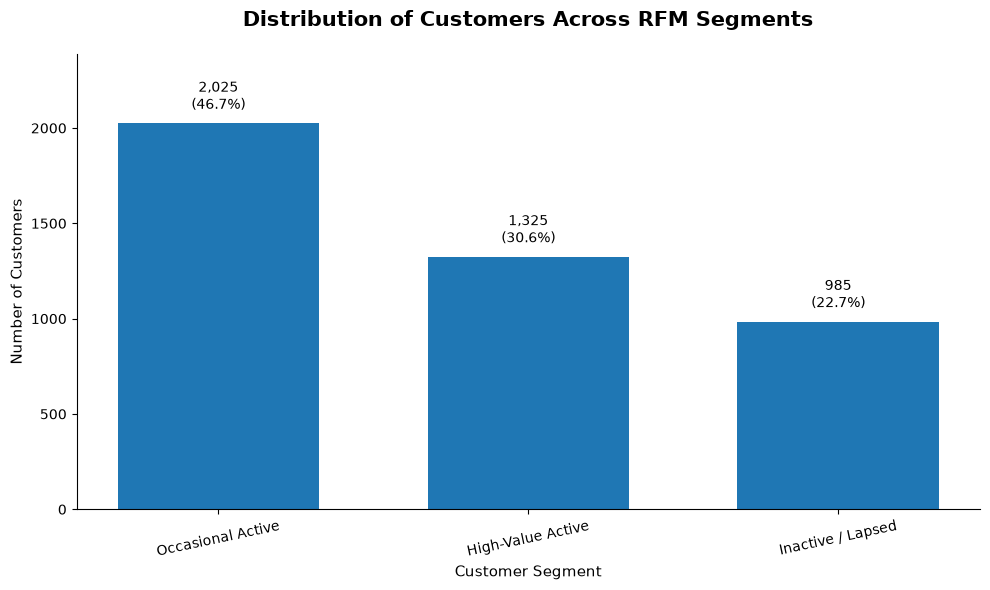

In [8]:
# Section 8.1 – Customer segment distribution chart

import matplotlib.pyplot as plt

cluster_distribution = (
    rfm_profile_data["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_labels = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

display_distribution = cluster_distribution.rename(
    index=cluster_labels
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    display_distribution.index,
    display_distribution.values,
    width=0.65
)

ax.set_title(
    "Distribution of Customers Across RFM Segments",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Customer Segment", fontsize=11)
ax.set_ylabel("Number of Customers", fontsize=11)

ax.set_ylim(0, display_distribution.max() * 1.18)

ax.tick_params(axis="x", rotation=12)

for bar, count in zip(bars, display_distribution.values):
    percentage = count / len(rfm_profile_data) * 100

    ax.annotate(
        f"{count:,}\n({percentage:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretation.** Occasional Active customers form the largest segment (46.71%), followed by High-Value Active customers (30.57%) and Inactive/Lapsed customers (22.72%). The distribution indicates that the retailer's customer base is not dominated exclusively by its highest-spending customers. There is a sizeable group of occasional purchasers, as well as a meaningful group with prolonged purchase inactivity. The three groups suggest different engagement priorities rather than a single uniform marketing approach.

### 8.2 Median RFM profile comparison

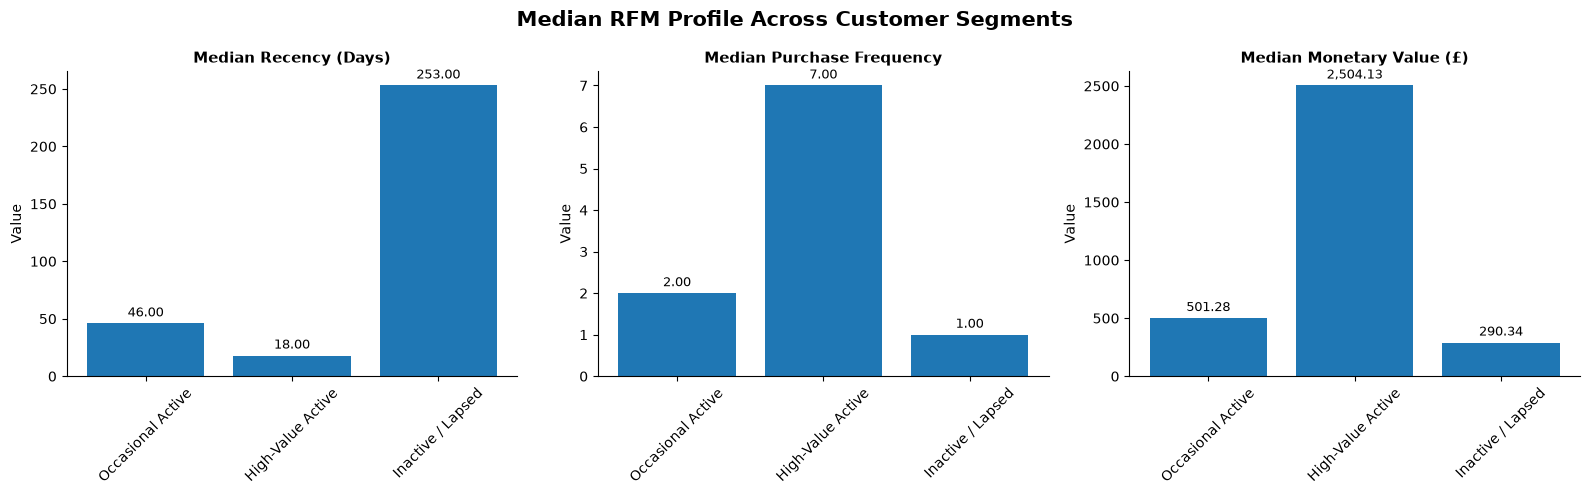

In [9]:
# Section 8.2 – RFM median profile comparison

import matplotlib.pyplot as plt

rfm_medians = (
    rfm_profile_data
    .groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .median()
)

segment_names = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

rfm_medians.index = rfm_medians.index.map(segment_names)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variables = [
    ("Recency", "Median Recency (Days)"),
    ("Frequency", "Median Purchase Frequency"),
    ("Monetary", "Median Monetary Value (£)")
]

for ax, (variable, title) in zip(axes, variables):

    values = rfm_medians[variable]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("Value")

    for bar, value in zip(bars, values.values):
        ax.annotate(
            f"{value:,.2f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Median RFM Profile Across Customer Segments",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Interpretation.** The median RFM chart highlights the separation between the segments. High-Value Active customers have the lowest recency (most recent purchasing), highest frequency and highest monetary value. Inactive/Lapsed customers have by far the highest recency and the lowest frequency and monetary value. Occasional Active customers lie between these profiles on most measures. Since recency is measured in days, a lower value indicates more recent activity.

### 8.3 Median extended behavioural profile comparison

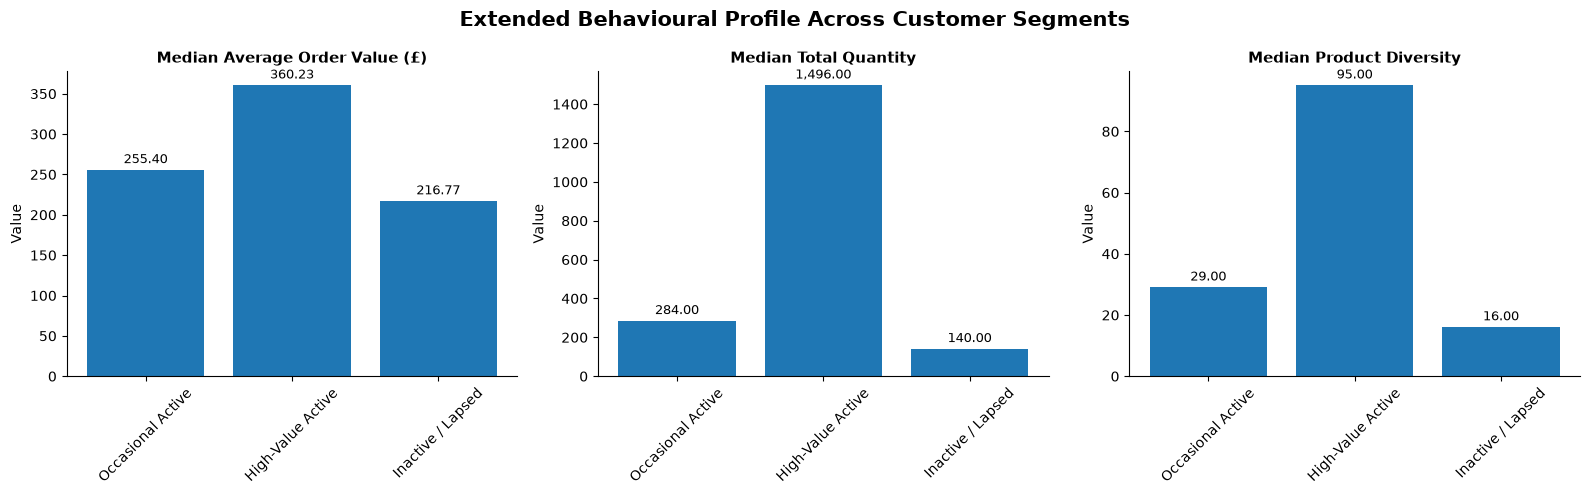

In [10]:
# Section 8.3 – Extended behavioural profile comparison

extended_medians = (
    rfm_profile_data
    .groupby("Cluster")[
        ["AverageOrderValue", "TotalQuantity", "ProductDiversity"]
    ]
    .median()
)

segment_names = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

extended_medians.index = extended_medians.index.map(segment_names)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variables = [
    ("AverageOrderValue", "Median Average Order Value (£)"),
    ("TotalQuantity", "Median Total Quantity"),
    ("ProductDiversity", "Median Product Diversity")
]

for ax, (variable, title) in zip(axes, variables):

    values = extended_medians[variable]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("Value")

    for bar, value in zip(bars, values.values):
        ax.annotate(
            f"{value:,.2f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Extended Behavioural Profile Across Customer Segments",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Interpretation.** The extended profile chart shows that High-Value Active customers also purchase a larger cumulative quantity and a wider variety of products, and have a higher typical order value. Occasional Active customers show moderate product engagement, while Inactive/Lapsed customers have the lowest median product diversity and quantity. These additional measures help make the segments more meaningful to business stakeholders.

### 8.4 PCA-Based Visualisation of Customer Segments

Principal Component Analysis (PCA) is used to reduce the three-dimensional, standardised RFM feature space into two principal components for visualisation.

The selected K-Means model was fitted using the original three RFM features. PCA is applied only after clustering to provide a two-dimensional representation of the customer segments.

The scatter plot illustrates how customers are distributed across the two principal components and provides a visual assessment of the separation and overlap between the identified clusters.

**Important:** PCA is used exclusively for visualisation. It does not replace the original RFM features or alter the selected K-Means cluster assignments.

PCA EXPLAINED VARIANCE
--------------------------------
Principal Component 1: 72.07%
Principal Component 2: 21.56%
Total explained variance: 93.63%


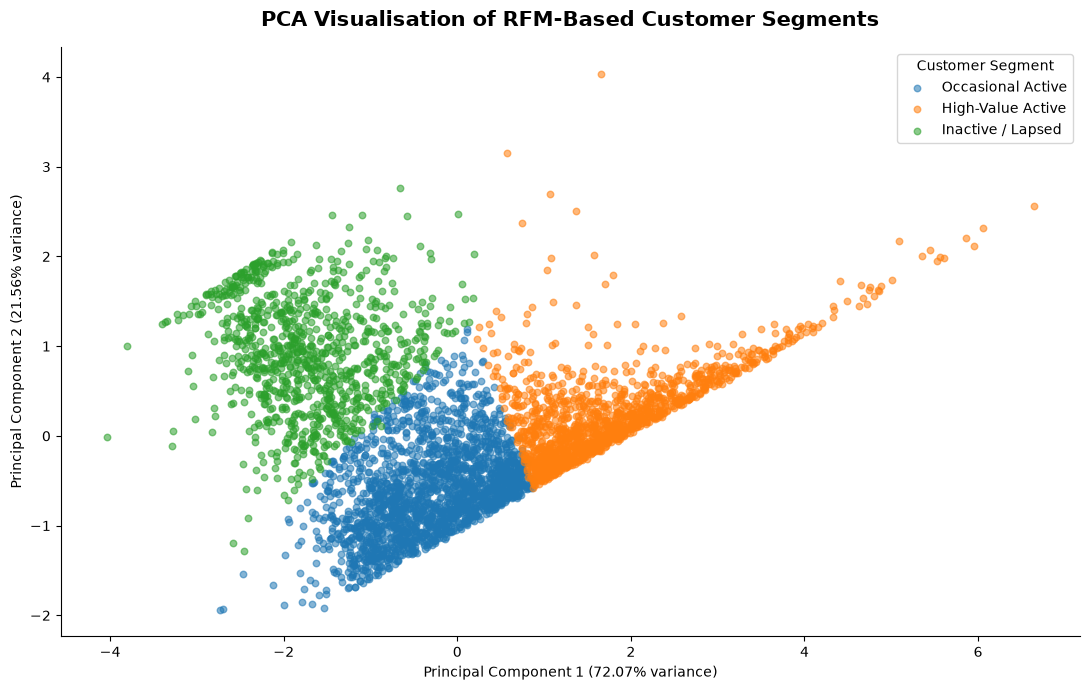

In [19]:

# Section 8.4 – PCA-based visualisation of customer segments

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use the standardised RFM features used by the selected K-Means model
# X_rfm contains Recency, Frequency and Monetary only.
if X_rfm.shape[1] != 3:
    raise ValueError("PCA visualisation expects exactly three RFM features.")

if X_rfm.isnull().any().any() or np.isinf(X_rfm).any().any():
    raise ValueError("RFM input contains missing or infinite values.")

# Fit PCA to reduce the three-dimensional RFM space to two dimensions
pca = PCA(n_components=2)
rfm_pca_components = pca.fit_transform(X_rfm)

# Create a plotting dataset with customer IDs
pca_plot_data = rfm_scaled[["CustomerID"]].copy()

# Attach cluster labels using CustomerID to preserve alignment
cluster_mapping = rfm_cluster_assignments.set_index("CustomerID")["Cluster"]

pca_plot_data["Cluster"] = pca_plot_data["CustomerID"].map(cluster_mapping)

# Add the two principal components
pca_plot_data["PC1"] = rfm_pca_components[:, 0]
pca_plot_data["PC2"] = rfm_pca_components[:, 1]

# Validate the PCA dataset
if pca_plot_data["Cluster"].isna().any():
    raise ValueError("Some customers do not have a cluster assignment.")

if len(pca_plot_data) != len(rfm_profile_data):
    raise ValueError("PCA data and customer profile data have different row counts.")

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_ * 100
total_explained_variance = explained_variance.sum()

print("PCA EXPLAINED VARIANCE")
print("--------------------------------")
print(f"Principal Component 1: {explained_variance[0]:.2f}%")
print(f"Principal Component 2: {explained_variance[1]:.2f}%")
print(f"Total explained variance: {total_explained_variance:.2f}%")

# Plot customer segments
segment_names = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

fig, ax = plt.subplots(figsize=(11, 7))

for cluster_id, segment_name in segment_names.items():

    cluster_data = pca_plot_data[
        pca_plot_data["Cluster"] == cluster_id
    ]

    ax.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=segment_name,
        alpha=0.55,
        s=22
    )

ax.set_title(
    "PCA Visualisation of RFM-Based Customer Segments",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    f"Principal Component 1 ({explained_variance[0]:.2f}% variance)"
)

ax.set_ylabel(
    f"Principal Component 2 ({explained_variance[1]:.2f}% variance)"
)

ax.legend(title="Customer Segment")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


**Interpretation of PCA Visualisation**

The PCA transformation reduced the three-dimensional standardised RFM feature space to two principal components, explaining 93.63% of the total variance. The first principal component explains 72.07%, while the second explains 21.56%.

The scatter plot reveals three distinguishable customer groupings. High-Value Active customers are concentrated predominantly towards the right side of the first principal component, while Inactive / Lapsed customers are concentrated mainly towards the upper-left region. Occasional Active customers occupy a relatively central and lower region of the plot.

Although some overlap is visible near the centre, the three segments demonstrate recognisable patterns in the two-dimensional projection. This provides visual support for the selected RFM-based segmentation.

The PCA visualisation is supplementary and does not independently establish cluster quality. The final model selection continues to rely on internal clustering metrics, stability, and the interpretability of customer profiles. Furthermore, the principal components represent combinations of the original RFM variables and should not be interpreted as individual business measures without examining their component loadings.

### 8.5 Customer Segment Profile Heatmap

A customer segment profile heatmap is used to compare the behavioural characteristics of the three identified customer segments across six variables: Recency, Frequency, Monetary Value, Average Order Value, Total Quantity and Product Diversity.

Since these variables are measured on different scales, their median values are standardised across customer segments before visualisation. This allows relative differences between segments to be compared without allowing variables with larger numerical scales to dominate the heatmap.

The original median values are retained in the accompanying customer segment summary for business interpretation. The heatmap is intended to highlight relative behavioural patterns rather than absolute values.

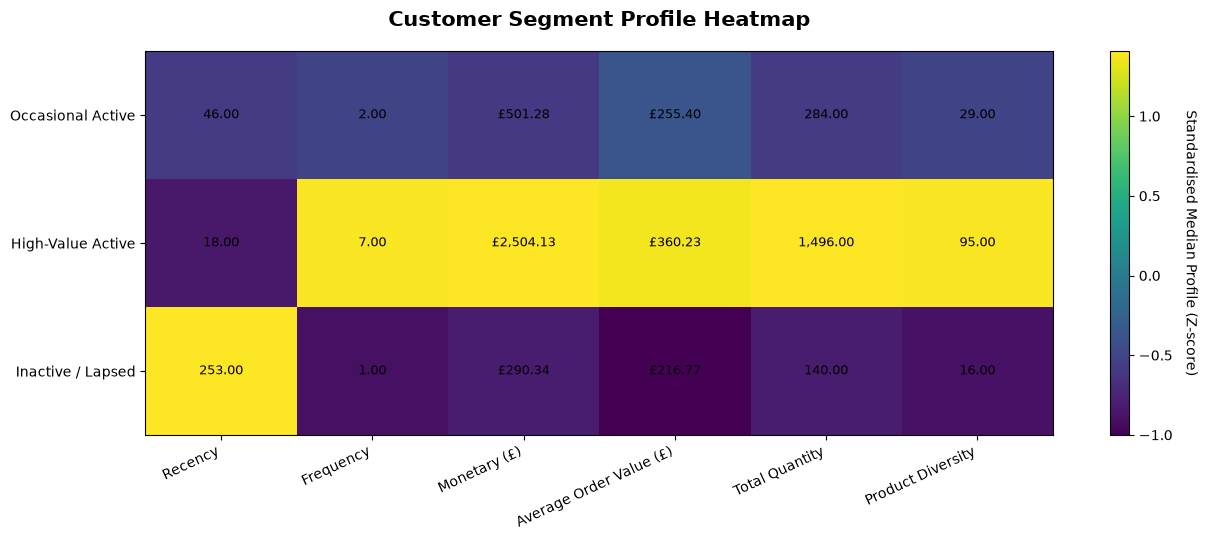

ORIGINAL MEDIAN VALUES USED IN THE HEATMAP
--------------------------------


,Recency,Frequency,Monetary (£),Average Order Value (£),Total Quantity,Product Diversity
Cluster,,,,,,
Occasional Active,46.0,2.0,501.28,255.40,284.0,29.0
High-Value Active,18.0,7.0,2504.13,360.23,1496.0,95.0
Inactive / Lapsed,253.0,1.0,290.34,216.76,140.0,16.0



STANDARDISED VALUES USED FOR COLOUR INTENSITY
--------------------------------


,Recency,Frequency,Monetary (£),Average Order Value (£),Total Quantity,Product Diversity
Cluster,,,,,,
Occasional Active,-0.57,-0.51,-0.60,-0.36,-0.59,-0.51
High-Value Active,-0.84,1.40,1.41,1.37,1.41,1.40
Inactive / Lapsed,1.41,-0.89,-0.81,-1.00,-0.82,-0.89


In [20]:

# Section 8.5 – Customer segment profile heatmap

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Select the six median-based customer profile variables
heatmap_columns = {
    "Median_Recency": "Recency",
    "Median_Frequency": "Frequency",
    "Median_Monetary": "Monetary (£)",
    "Median_AOV": "Average Order Value (£)",
    "Median_Total_Quantity": "Total Quantity",
    "Median_Product_Diversity": "Product Diversity"
}

# Extract the median profile values
heatmap_data = final_segment_summary[
    list(heatmap_columns.keys())
].rename(columns=heatmap_columns).copy()

# Standardise each variable across the three customer segments
# This makes variables with different units comparable.
heatmap_standardised = (
    heatmap_data - heatmap_data.mean()
) / heatmap_data.std(ddof=0)

# Create the heatmap
fig, ax = plt.subplots(figsize=(13, 5.5))

image = ax.imshow(
    heatmap_standardised,
    aspect="auto"
)

# Configure axis labels
ax.set_xticks(range(len(heatmap_standardised.columns)))
ax.set_xticklabels(
    heatmap_standardised.columns,
    rotation=25,
    ha="right"
)

ax.set_yticks(range(len(heatmap_standardised.index)))
ax.set_yticklabels(heatmap_standardised.index)

ax.set_title(
    "Customer Segment Profile Heatmap",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Annotate each cell with its original median value
for row in range(len(heatmap_data.index)):
    for col in range(len(heatmap_data.columns)):

        value = heatmap_data.iloc[row, col]

        if col in [2, 3]:
            annotation = f"£{value:,.2f}"
        else:
            annotation = f"{value:,.2f}"

        ax.text(
            col,
            row,
            annotation,
            ha="center",
            va="center",
            fontsize=9
        )

# Add colour bar explaining standardised values
colourbar = fig.colorbar(image, ax=ax)
colourbar.set_label(
    "Standardised Median Profile (Z-score)",
    rotation=270,
    labelpad=18
)

plt.tight_layout()
plt.show()

# Display the original median values for reference
print("ORIGINAL MEDIAN VALUES USED IN THE HEATMAP")
print("--------------------------------")
display(heatmap_data.round(2))

print("\nSTANDARDISED VALUES USED FOR COLOUR INTENSITY")
print("--------------------------------")
display(heatmap_standardised.round(2))


**Interpretation of Customer Segment Profile Heatmap**

The heatmap provides a comparative view of the behavioural characteristics of the three customer segments using standardised median values across six variables.

The High-Value Active segment demonstrates the strongest engagement profile, with above-average values for purchase frequency, monetary value, average order value, total quantity and product diversity. It also has the lowest median recency of 18 days, indicating more recent purchasing activity.

The Occasional Active segment displays relatively moderate values across the behavioural measures. Its median purchase frequency of two invoices and median monetary value of £501.28 suggest that these customers are less engaged than the High-Value Active segment but remain comparatively recent purchasers.

The Inactive / Lapsed segment exhibits a contrasting pattern. It has the highest median recency of 253 days, alongside the lowest median purchase frequency, monetary value, average order value, total quantity and product diversity. This indicates limited recent purchasing activity and lower historical engagement.

Overall, the heatmap reinforces the behavioural distinctions identified through the RFM-based K-Means model. It also demonstrates how the additional behavioural variables help provide a richer interpretation of the selected customer segments. The standardised values are used only for visual comparison, while the original median values provide the basis for business interpretation.

## 9. Supplementary geographical profiling by country

Country was deliberately excluded from the clustering features. It is examined only after the final clusters have been assigned, to understand how the identified segments are distributed across the countries recorded in the transaction data.

The country mapping follows the same merchandise-only transaction cleaning rules used to create the customer features in Notebook 04. Where a customer has transactions recorded in more than one country, the country with the largest number of qualifying transaction records is assigned as that customer's **primary recorded country** for this descriptive analysis. This is a profiling convention, not a claim about residence, nationality or permanent location.

### 9.1 Verify the raw transaction dataset

In [11]:
# Section 9.1 – Verify availability of the original transaction dataset

RAW_DIR = PROJECT_ROOT / "data" / "raw"

raw_file = RAW_DIR / "Online Retail.xlsx"

print("RAW DATA VERIFICATION")
print("--------------------------------")
print("Raw dataset path:", raw_file)
print("File available:", raw_file.exists())

if raw_file.exists():
    print("File size (MB):", round(raw_file.stat().st_size / (1024 * 1024), 2))

RAW DATA VERIFICATION
--------------------------------
Raw dataset path: C:\Users\yadav\OneDrive\Desktop\Online_Retail_Customer_Segmentation\data\raw\Online Retail.xlsx
File available: True
File size (MB): 22.62


**Interpretation.** The original Online Retail transaction file is available in the project's raw data directory. It contains 541,909 transaction records. The country analysis starts from this source so that the customer-country mapping can be recreated using the same cleaning rules as the merchandise-only customer-level dataset.

### 9.2 Inspect country coverage in the raw data

In [12]:
# Section 9.2 – Inspect country information in the raw transaction dataset

raw_df = pd.read_excel(
    raw_file,
    usecols=["InvoiceNo", "StockCode", "Quantity", "UnitPrice",
             "CustomerID", "Country"]
)

print("RAW TRANSACTION DATA")
print("--------------------------------")

print("Shape:", raw_df.shape)

print("\nMissing values:")
display(raw_df[["CustomerID", "Country"]].isnull().sum())

print("\nNumber of unique countries:",
      raw_df["Country"].nunique())

print("\nTop 15 countries by transaction records:")
display(
    raw_df["Country"]
    .value_counts()
    .head(15)
    .to_frame("Transaction_Records")
)

print("\nSample records:")
display(raw_df.head())

RAW TRANSACTION DATA
--------------------------------
Shape: (541909, 6)

Missing values:


CustomerID    135080
Country            0
dtype: int64


Number of unique countries: 38

Top 15 countries by transaction records:


,Transaction_Records
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519



Sample records:


,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID,Country
0,536365,85123A,6,2.55,17850.0,United Kingdom
1,536365,71053,6,3.39,17850.0,United Kingdom
2,536365,84406B,8,2.75,17850.0,United Kingdom
3,536365,84029G,6,3.39,17850.0,United Kingdom
4,536365,84029E,6,3.39,17850.0,United Kingdom


**Interpretation.** The raw transaction data contain 38 distinct country labels. Transaction-record counts are not the same as customer counts: a customer may generate many transaction records, so the raw country frequency table should not be interpreted as the geographic distribution of unique customers. Customer-level country counts are calculated after applying the project cleaning rules.

### 9.3 Recreate the cleaned customer-country dataset

In [13]:
# Section 9.3 – Create customer-level country mapping

# Reload the complete dataset to preserve the original
# duplicate-removal and preprocessing logic
country_df = pd.read_excel(raw_file)

initial_rows = len(country_df)

# Step 1: Remove exact duplicate records
country_df = country_df.drop_duplicates()

# Step 2: Exclude cancellation invoices
country_df = country_df[
    ~country_df["InvoiceNo"].astype(str).str.startswith("C")
]

# Step 3: Retain identified customers
country_df = country_df[
    country_df["CustomerID"].notna()
]

# Step 4: Retain positive transaction quantities and prices
country_df = country_df[
    (country_df["Quantity"] > 0) &
    (country_df["UnitPrice"] > 0)
]

# Step 5: Exclude non-merchandise stock codes
excluded_codes = ["POST", "DOT", "M"]

country_df = country_df[
    ~country_df["StockCode"].astype(str).isin(excluded_codes)
]

print("COUNTRY PROFILING DATA PREPARATION")
print("--------------------------------")
print("Initial transaction rows:", initial_rows)
print("Rows after cleaning:", len(country_df))
print("Unique customers:", country_df["CustomerID"].nunique())

# Step 6: Count distinct countries associated with each customer
customer_country_counts = (
    country_df.groupby("CustomerID")["Country"]
    .nunique()
)

print("\nCUSTOMER-COUNTRY ASSOCIATION")
print("--------------------------------")

print("Customers associated with exactly one country:",
      (customer_country_counts == 1).sum())

print("Customers associated with multiple countries:",
      (customer_country_counts > 1).sum())

print("Customers without country information:",
      (customer_country_counts == 0).sum())

# Inspect customers associated with multiple countries
multi_country_customers = customer_country_counts[
    customer_country_counts > 1
]

if len(multi_country_customers) > 0:
    print("\nCustomers associated with multiple countries:")
    display(
        country_df[
            country_df["CustomerID"].isin(
                multi_country_customers.index
            )
        ][["CustomerID", "Country"]]
        .drop_duplicates()
        .sort_values("CustomerID")
        .head(20)
    )

COUNTRY PROFILING DATA PREPARATION
--------------------------------
Initial transaction rows: 541909
Rows after cleaning: 391298
Unique customers: 4335

CUSTOMER-COUNTRY ASSOCIATION
--------------------------------
Customers associated with exactly one country: 4327
Customers associated with multiple countries: 8
Customers without country information: 0

Customers associated with multiple countries:


,CustomerID,Country
34293,12370.0,Austria
29732,12370.0,Cyprus
383089,12394.0,Denmark
177881,12394.0,Belgium
34461,12417.0,Belgium
171221,12417.0,Spain
239276,12422.0,Switzerland
63100,12422.0,Australia
168399,12429.0,Austria
20017,12429.0,Denmark


**Interpretation.** Applying the established cleaning rules reduces the raw data to 391,298 qualifying merchandise transaction rows associated with 4,335 identified customers. This matches the merchandise-only transaction population used in the earlier feature-engineering phase, providing a consistency check for the country profiling exercise.

The output indicates that 4,327 customers have transactions recorded in one country and 8 have transactions in more than one country. No customer lacks country information in the cleaned dataset. The small number of multi-country customers is examined before assigning a primary recorded country.

### 9.4 Examine customers associated with multiple countries

In [14]:
# Section 9.4 – Examine multi-country customers

multi_country_details = (
    country_df[
        country_df["CustomerID"].isin(
            multi_country_customers.index
        )
    ]
    .groupby(["CustomerID", "Country"])
    .size()
    .reset_index(name="Transaction_Count")
    .sort_values(
        ["CustomerID", "Transaction_Count"],
        ascending=[True, False]
    )
)

display(multi_country_details)

# Check whether any customer has a tie in transaction counts
max_counts = (
    multi_country_details
    .groupby("CustomerID")["Transaction_Count"]
    .transform("max")
)

top_countries = multi_country_details[
    multi_country_details["Transaction_Count"] == max_counts
]

tie_counts = top_countries.groupby("CustomerID").size()

print("\nNumber of customers with tied leading countries:",
      (tie_counts > 1).sum())

,CustomerID,Country,Transaction_Count
1,12370.0,Cyprus,158
0,12370.0,Austria,7
2,12394.0,Belgium,20
3,12394.0,Denmark,5
4,12417.0,Belgium,161
5,12417.0,Spain,22
6,12422.0,Australia,21
7,12422.0,Switzerland,17
9,12429.0,Denmark,74
8,12429.0,Austria,20



Number of customers with tied leading countries: 0


**Interpretation.** Eight customers have qualifying transactions recorded in more than one country. The country with the largest number of transaction records is the leading country for each of these customers, and no customer has a tie between leading countries. Assigning the most frequently recorded country therefore provides a deterministic rule for the supplementary profile. It should not be interpreted as establishing the customer's actual residence.

### 9.5 Assign a primary recorded country and join segment labels

In [15]:
# Section 9.5 – Assign one primary recorded country to each customer

# Count qualifying transaction records by customer and country
customer_country_mapping = (
    country_df
    .groupby(["CustomerID", "Country"])
    .size()
    .reset_index(name="Transaction_Count")
)

# Sort so that the country with the highest transaction count comes first
customer_country_mapping = customer_country_mapping.sort_values(
    ["CustomerID", "Transaction_Count", "Country"],
    ascending=[True, False, True]
)

# Assign the most frequently recorded country to each customer
customer_country_mapping = (
    customer_country_mapping
    .drop_duplicates(subset="CustomerID", keep="first")
    [["CustomerID", "Country"]]
)

# Merge country information with customer-level features and cluster labels
customer_country_profile = (
    customer_features
    .merge(
        customer_country_mapping,
        on="CustomerID",
        how="left",
        validate="one_to_one"
    )
    .merge(
        rfm_cluster_assignments,
        on="CustomerID",
        how="left",
        validate="one_to_one"
    )
)

# Verify mapping
print("CUSTOMER-LEVEL COUNTRY MAPPING")
print("--------------------------------")

print("Total customers:", len(customer_country_profile))
print("Unique customer IDs:",
      customer_country_profile["CustomerID"].nunique())

print("Missing country assignments:",
      customer_country_profile["Country"].isna().sum())

print("Duplicate customer IDs:",
      customer_country_profile["CustomerID"].duplicated().sum())

print("\nNumber of countries:",
      customer_country_profile["Country"].nunique())

print("\nTop 15 countries by customer count:")

display(
    customer_country_profile["Country"]
    .value_counts()
    .head(15)
    .rename_axis("Country")
    .reset_index(name="Customer_Count")
)

CUSTOMER-LEVEL COUNTRY MAPPING
--------------------------------
Total customers: 4335
Unique customer IDs: 4335
Missing country assignments: 0
Duplicate customer IDs: 0

Number of countries: 37

Top 15 countries by customer count:


,Country,Customer_Count
0,United Kingdom,3917
1,Germany,94
2,France,87
3,Spain,29
4,Belgium,24
5,Switzerland,20
6,Portugal,19
7,Italy,14
8,Finland,12
9,Norway,10


**Interpretation.** The mapping produces one country assignment for each of the 4,335 customers, with no missing assignments or duplicate customer IDs. The cleaned customer population is distributed across 37 countries. The United Kingdom accounts for 3,917 customers (90.36%), making it by far the dominant market in this dataset. This imbalance is important when interpreting country-level segment proportions.

### 9.6 Compare segment composition across countries

In [16]:
# Section 9.6 – Country-wise customer segment distribution

# Customer counts by country and cluster
country_cluster_counts = pd.crosstab(
    customer_country_profile["Country"],
    customer_country_profile["Cluster"]
)

# Rename cluster columns
country_cluster_counts = country_cluster_counts.rename(
    columns={
        0: "Occasional Active",
        1: "High-Value Active",
        2: "Inactive / Lapsed"
    }
)

# Calculate percentages within each country
country_cluster_percentages = (
    country_cluster_counts
    .div(country_cluster_counts.sum(axis=1), axis=0)
    * 100
)

# Sort countries by total customer count
country_cluster_counts["Total Customers"] = (
    country_cluster_counts.sum(axis=1)
)

country_cluster_counts = country_cluster_counts.sort_values(
    "Total Customers",
    ascending=False
)

country_cluster_percentages = country_cluster_percentages.reindex(
    country_cluster_counts.index
)

print("COUNTRY-WISE CUSTOMER SEGMENT COUNTS")
print("--------------------------------")

display(country_cluster_counts.head(15))

print("\nCOUNTRY-WISE CUSTOMER SEGMENT DISTRIBUTION (%)")
print("--------------------------------")

display(country_cluster_percentages.head(15).round(2))

COUNTRY-WISE CUSTOMER SEGMENT COUNTS
--------------------------------


Cluster,Occasional Active,High-Value Active,Inactive / Lapsed,Total Customers
Country,,,,
United Kingdom,1832,1190,895,3917
Germany,43,34,17,94
France,38,31,18,87
Spain,16,8,5,29
Belgium,7,12,5,24
Switzerland,10,6,4,20
Portugal,8,5,6,19
Italy,7,3,4,14
Finland,7,4,1,12



COUNTRY-WISE CUSTOMER SEGMENT DISTRIBUTION (%)
--------------------------------


Cluster,Occasional Active,High-Value Active,Inactive / Lapsed
Country,,,
United Kingdom,46.77,30.38,22.85
Germany,45.74,36.17,18.09
France,43.68,35.63,20.69
Spain,55.17,27.59,17.24
Belgium,29.17,50.00,20.83
Switzerland,50.00,30.00,20.00
Portugal,42.11,26.32,31.58
Italy,50.00,21.43,28.57
Finland,58.33,33.33,8.33


**Interpretation.** Country-wise segment counts and within-country percentages provide a descriptive view of how the three customer segments are represented geographically. The United Kingdom contributes most observations because it represents 90.36% of customers. Some other countries have very small customer counts; their percentages can therefore change substantially with only a few customers.

These results are supplementary and should not be used to make strong claims about differences between national markets. The country distribution is not balanced, and the analysis does not control for differences in market size, customer acquisition or transaction exposure.

## 10. Final model evaluation summary

The table below consolidates the candidate-model results and identifies the selected solution. This is the final model-selection record for Phase 6.

In [17]:
# Section 10 – Final model evaluation summary

# Identify the selected model from our candidate comparison
selected_model_name = "RFM | K-Means | K=3"

# Extract selected model metrics
selected_model_metrics = final_model_comparison[
    final_model_comparison["Model"] == selected_model_name
].copy()

# Create final evaluation summary
final_evaluation_summary = final_model_comparison[
    [
        "Model",
        "Number_of_Clusters",
        "Silhouette_Score",
        "Davies_Bouldin_Index",
        "Calinski_Harabasz_Index"
    ]
].copy()

# Add selection status
final_evaluation_summary["Selection_Status"] = (
    final_evaluation_summary["Model"]
    .apply(
        lambda x: "Selected Model"
        if x == selected_model_name
        else "Alternative Model"
    )
)

print("FINAL MODEL EVALUATION SUMMARY")
print("--------------------------------")

display(final_evaluation_summary.round(4))

print("\nSELECTED MODEL")
print("--------------------------------")

display(selected_model_metrics.round(4))

FINAL MODEL EVALUATION SUMMARY
--------------------------------


,Model,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index,Selection_Status
0,RFM | K-Means | K=3,3,0.4151,0.8269,4378.5206,Selected Model
1,RFM | Hierarchical | K=2,2,0.3965,0.8371,3276.0686,Alternative Model
2,RFM | Hierarchical | K=3,3,0.3956,0.8669,4151.0791,Alternative Model
3,Extended | K-Means | K=2,2,0.3511,1.0616,3116.7941,Alternative Model
4,Reduced Extended | K-Means | K=2,2,0.3360,1.1176,2802.5822,Alternative Model
5,Extended | Hierarchical | K=2,2,0.3237,1.0306,2510.9298,Alternative Model



SELECTED MODEL
--------------------------------


,Model,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,RFM | K-Means | K=3,3,0.4151,0.8269,4378.5206


**Final model decision.** RFM K-Means with three clusters is retained as the selected model. It has the highest Silhouette and Calinski–Harabasz scores and the lowest Davies–Bouldin score among the six candidate models evaluated in this notebook. The decision is also supported by the clear customer profiles and the robustness checks conducted in Notebook 05.

The earlier robustness analysis found that the RFM K-Means solution was highly consistent across repeated random initialisations. The StandardScaler-versus-RobustScaler comparison produced an Adjusted Rand Index (ARI) of 0.9488, while the outlier sensitivity comparison produced an ARI of 0.9974. These values indicate strong agreement between the compared partitions; ARI measures similarity between cluster assignments and is not a measure of predictive accuracy.

The model-selection conclusion is specific to the dataset, feature definitions and experiments conducted in this project.

## 11. Final customer segment summary

The final summary table combines segment size, median RFM values, supplementary behavioural measures and a concise commercial interpretation. It is intended to serve as the principal reference table for the final report and presentation.

In [18]:
# Section 11 – Final customer segment summary

# Calculate the final customer segment profiles
final_segment_summary = (
    rfm_profile_data
    .groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Median_AOV=("AverageOrderValue", "median"),
        Median_Total_Quantity=("TotalQuantity", "median"),
        Median_Product_Diversity=("ProductDiversity", "median")
    )
)

# Calculate customer percentages
final_segment_summary["Customer_Percentage"] = (
    final_segment_summary["Customer_Count"]
    / len(rfm_profile_data)
    * 100
)

# Assign descriptive segment names
segment_names = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

final_segment_summary.index = (
    final_segment_summary.index.map(segment_names)
)

# Add commercial interpretations
segment_interpretations = {
    "Occasional Active":
        "Relatively recent but infrequent purchasers with moderate spending and product engagement.",

    "High-Value Active":
        "Highly engaged customers with frequent purchases, higher spending and greater product diversity.",

    "Inactive / Lapsed":
        "Customers with long purchase inactivity, low frequency and relatively low historical spending."
}

final_segment_summary["Commercial_Interpretation"] = (
    final_segment_summary.index.map(segment_interpretations)
)

# Arrange columns
final_segment_summary = final_segment_summary[
    [
        "Customer_Count",
        "Customer_Percentage",
        "Median_Recency",
        "Median_Frequency",
        "Median_Monetary",
        "Median_AOV",
        "Median_Total_Quantity",
        "Median_Product_Diversity",
        "Commercial_Interpretation"
    ]
]

print("FINAL CUSTOMER SEGMENT SUMMARY")
print("--------------------------------")

display(final_segment_summary.round(2))

# Validate customer coverage
print("\nVALIDATION")
print("--------------------------------")
print("Total customers:",
      final_segment_summary["Customer_Count"].sum())

print("Total segment percentage:",
      round(final_segment_summary["Customer_Percentage"].sum(), 2))

FINAL CUSTOMER SEGMENT SUMMARY
--------------------------------


,Customer_Count,Customer_Percentage,Median_Recency,Median_Frequency,Median_Monetary,Median_AOV,Median_Total_Quantity,Median_Product_Diversity,Commercial_Interpretation
Cluster,,,,,,,,,
Occasional Active,2025,46.71,46.0,2.0,501.28,255.40,284.0,29.0,Relatively recent but infrequent purchasers wi...
High-Value Active,1325,30.57,18.0,7.0,2504.13,360.23,1496.0,95.0,Highly engaged customers with frequent purchas...
Inactive / Lapsed,985,22.72,253.0,1.0,290.34,216.76,140.0,16.0,"Customers with long purchase inactivity, low f..."



VALIDATION
--------------------------------
Total customers: 4335
Total segment percentage: 100.0


**Interpretation and validation.** The final summary covers all 4,335 customers, and the segment percentages sum to 100%. The High-Value Active segment is smaller than the Occasional Active segment but has substantially higher typical purchase frequency, monetary contribution and product diversity. The Inactive/Lapsed segment is characterised by long purchase inactivity and lower historical engagement. These distinctions provide the basis for the differentiated recommendations in the next section.

## 12. Business recommendations

The recommendations below translate the observed customer profiles into potential engagement strategies. They are hypotheses for business action, not interventions tested by the clustering analysis.

### Business Recommendations

Based on the identified customer segments, differentiated customer engagement strategies are recommended.

**1. Occasional Active Customers**

As the largest customer segment, these customers represent an opportunity to strengthen repeat purchasing behaviour. The business could introduce personalised product recommendations, targeted cross-selling campaigns and incentives for repeat purchases. The objective would be to increase purchase frequency and product engagement.

**2. High-Value Active Customers**

These customers demonstrate the strongest purchasing engagement and monetary contribution. Retention should therefore be a priority. Potential interventions include loyalty programmes, personalised offers, exclusive product access and priority customer support. These initiatives could help maintain customer engagement and strengthen long-term relationships.

**3. Inactive / Lapsed Customers**

Customers in this segment have not purchased for a considerable period and generally exhibit low historical purchasing frequency. Targeted reactivation campaigns, personalised communication and carefully designed win-back incentives could be tested to encourage renewed purchasing activity.

**Implementation and measurement**

The proposed interventions should be evaluated using measurable indicators such as repeat purchase rate, customer retention rate, reactivation rate, purchase frequency and campaign conversion rate. Controlled campaign experiments could help establish whether these interventions produce measurable improvements.

These recommendations are based on observed historical purchasing patterns. Their effectiveness has not been tested within the present clustering analysis.

**Implementation note.** The retailer should pilot these interventions and evaluate them using measurable outcomes. Where feasible, campaign effectiveness should be assessed through controlled experiments or an appropriate comparison group. This would help distinguish genuine incremental impact from purchases that would have occurred without the intervention.

## 13. Limitations and responsible machine learning

The customer segmentation analysis provides useful insights into purchasing behaviour, but several limitations should be considered when interpreting and applying the results.

### Limitations and Responsible Machine Learning

The customer segmentation analysis provides useful insights into purchasing behaviour, but several limitations should be considered when interpreting and applying the results.

**1. Dataset representativeness**

The analysis uses historical transaction data from a single online retailer covering 2010–2011. Consequently, the identified customer segments may not represent customers of other retailers, industries or contemporary online retail environments.

**2. Geographical imbalance**

The United Kingdom accounts for approximately 90.36% of the customer population. Although geographical profiling was conducted, the relatively small customer populations in several other countries limit the reliability of cross-country comparisons.

**3. Feature selection**

The clustering models use RFM and selected extended purchasing characteristics. Other dimensions, such as customer demographics, preferences, marketing interactions and customer satisfaction, are not available in the analytical dataset. Therefore, the identified segments represent purchasing behaviour rather than a complete understanding of customer characteristics.

**4. Influence of extreme observations**

Customer spending and purchasing quantities exhibit substantial skewness. Although transformations, scaling comparisons and outlier sensitivity analysis were performed, distance-based clustering can still be influenced by extreme observations.

**5. Interpretation of clusters**

K-Means identifies mathematical groupings based on feature similarity. Labels such as High-Value Active, Occasional Active and Inactive/Lapsed are analytical interpretations of the resulting profiles, rather than predefined or objectively correct customer categories.

**6. Historical and temporal limitations**

The segmentation reflects purchasing activity during the observed historical period. Customer behaviour may change over time, and the analysis does not predict future purchases, customer churn or transitions between segments.

**7. Responsible use and privacy**

Customer identifiers were used for aggregation and analytical purposes rather than as behavioural predictors. Although the dataset is deidentified, customer-level information should still be handled responsibly, with appropriate access controls and data protection practices.

The resulting segments should support business decision-making rather than replace human judgement. Any customer engagement strategy based on these segments should be evaluated before implementation. The clustering analysis identifies behavioural associations and does not establish causal relationships.

## 14. Phase 6 conclusion and research question assessment

The customer segmentation analysis demonstrates that unsupervised machine learning can identify meaningful groups of customers based on their historical purchasing behaviour.

### RQ1. What distinct customer segments can be identified using RFM features?

The selected RFM K-Means model with three clusters identified three segments among 4,335 customers: Occasional Active (2,025; 46.71%), High-Value Active (1,325; 30.57%) and Inactive/Lapsed (985; 22.72%). The groups differ in recency, purchase frequency and cumulative monetary contribution.

### RQ2. How do the segments differ in purchasing behaviour, spending and product diversity?

The segments also differ on the supplementary behavioural measures. High-Value Active customers have the highest median monetary value (£2,504.13), frequency (7 invoices), average order value (£360.23), total quantity (1,496) and product diversity (95). Occasional Active customers show moderate engagement, while Inactive/Lapsed customers have the longest median recency (253 days), a median frequency of one invoice and lower typical spending and product diversity.

### RQ3. Does incorporating additional behavioural features improve segmentation compared with RFM?

The Extended K-Means K=2 model achieved a Silhouette Score of 0.3511, compared with 0.4151 for RFM K-Means K=3. Reduced Extended K-Means K=2 achieved 0.3360. The extended feature sets therefore did not improve the internal evaluation results in the experiments conducted. However, the additional variables remained useful for profiling and interpreting the RFM-derived segments. Because the models use feature spaces of different dimensionality, metric comparisons should be interpreted cautiously.

### RQ4. How do K-Means and Hierarchical Clustering compare?

For the RFM feature set, K-Means K=3 achieved a Silhouette Score of 0.4151, Davies–Bouldin Index of 0.8269 and Calinski–Harabasz Index of 4,378.52. RFM Hierarchical K=3 achieved 0.3956, 0.8669 and 4,151.08 respectively. K-Means performed better on all three metrics in this three-cluster comparison. The three-cluster K-Means and Hierarchical partitions showed an ARI of 0.7652 in the preceding modelling analysis, indicating meaningful but not identical assignments.

### Overall conclusion

Among the candidate models evaluated, RFM K-Means with three clusters provides the strongest overall balance of internal clustering quality, stability, simplicity and business interpretability. The analysis identifies differentiated customer groups that can inform retention, repeat-purchase and reactivation strategies. The segments describe historical purchasing behaviour; they are not predictions of future customer behaviour and do not establish causal relationships.

The findings should be applied with awareness of the dataset's historical period, single-retailer scope and geographical imbalance. Any proposed customer engagement strategy should be tested and monitored before being scaled.

## 15. Phase 6 completion checklist

The following outputs complete the analytical and interpretive work for this phase:

- Candidate clustering models re-evaluated using internal validation metrics.
- Preferred model selected and justified.
- RFM and supplementary behavioural profiles interpreted.
- Segment distribution and profile charts produced.
- Country-wise profiling completed as a supplementary analysis.
- Final customer segment summary validated against the full customer population.
- Commercial recommendations developed with measurable evaluation indicators.
- Limitations and responsible-use considerations documented.
- Research questions addressed in the phase conclusion.

**Transition to Phase 7:** The next phase will consolidate the project into the final report, reproducible notebook package, presentation and other required submission materials. The notebook should be executed from top to bottom in the final project environment before submission, and all figures/tables intended for the report should be exported to the appropriate output folders.